# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import OGSTDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv

## Visualize images and objects witn bounding boxes

Total number of patches: 760


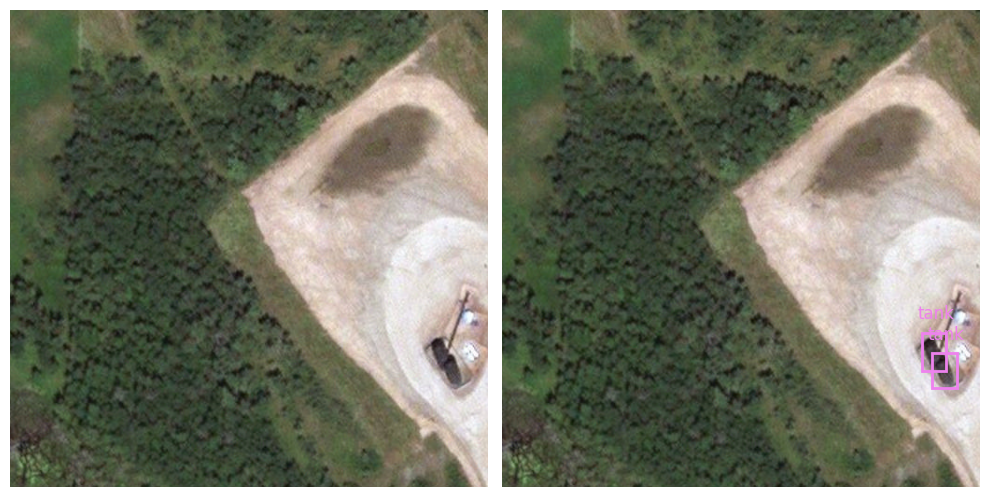

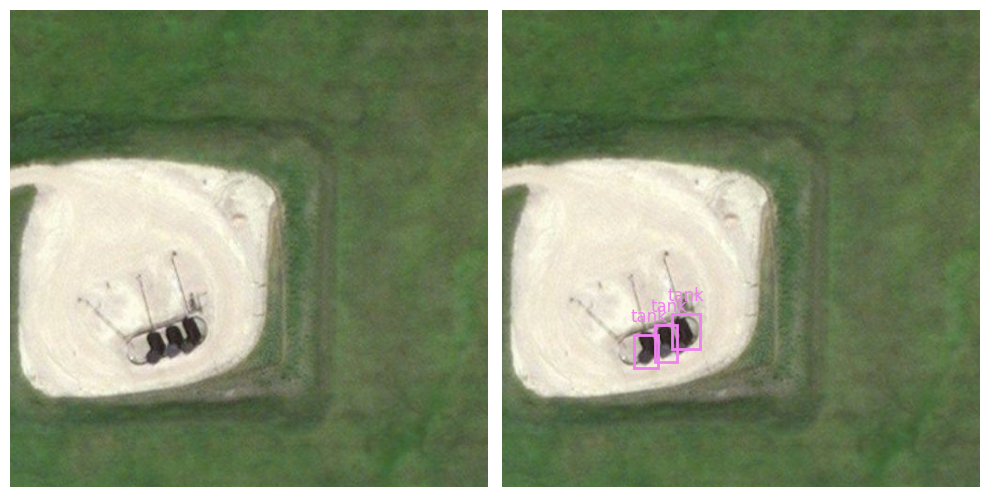

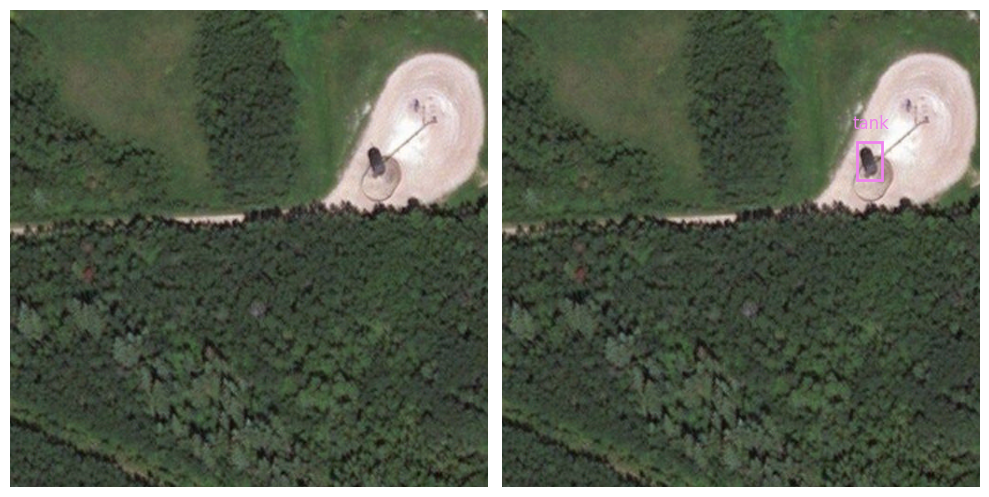

In [18]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/OGST/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OGST/annotations/",
}
dataset = OGSTDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

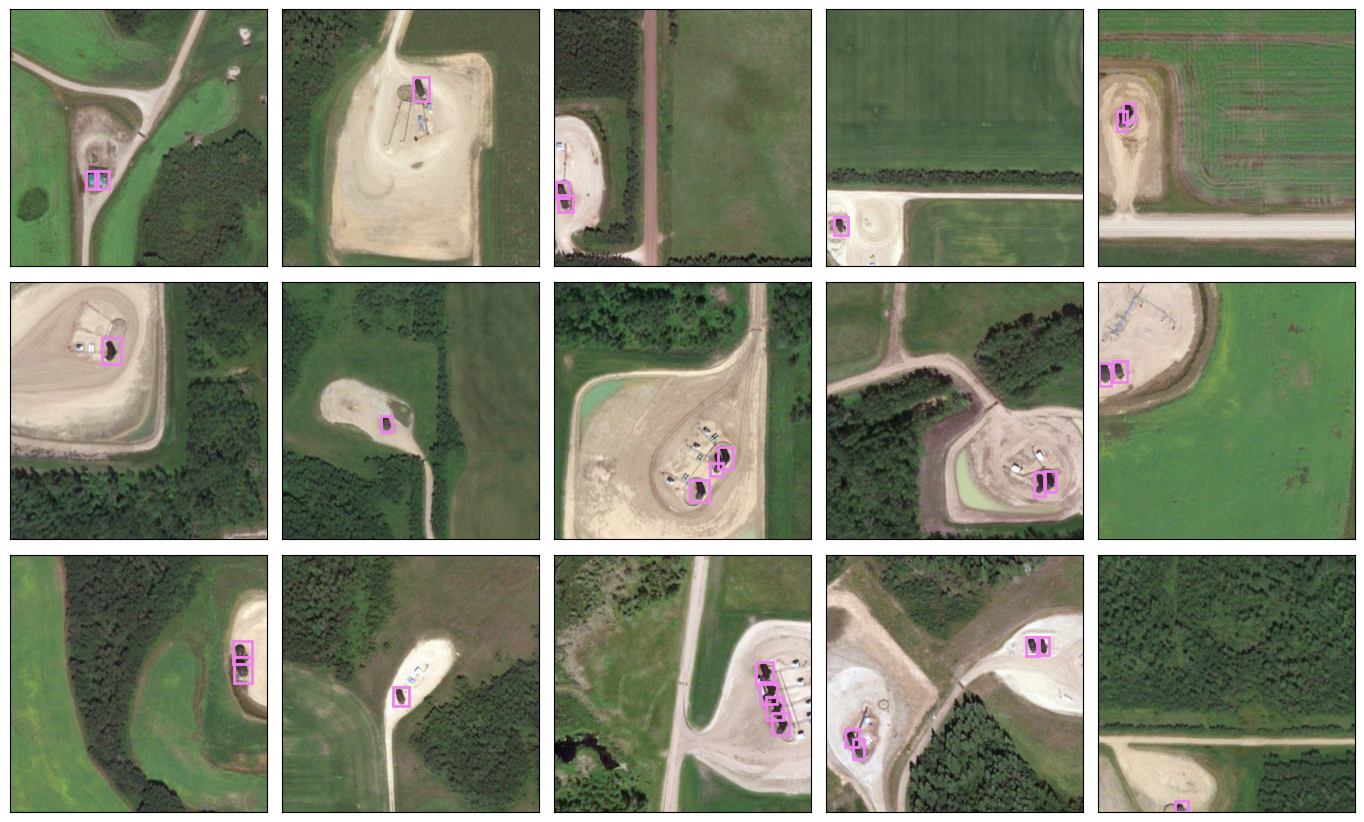

In [19]:
dataset.show_batch(15);

In [20]:
dataset.data_distribution_table()

,Label,Count
0,tank,1671


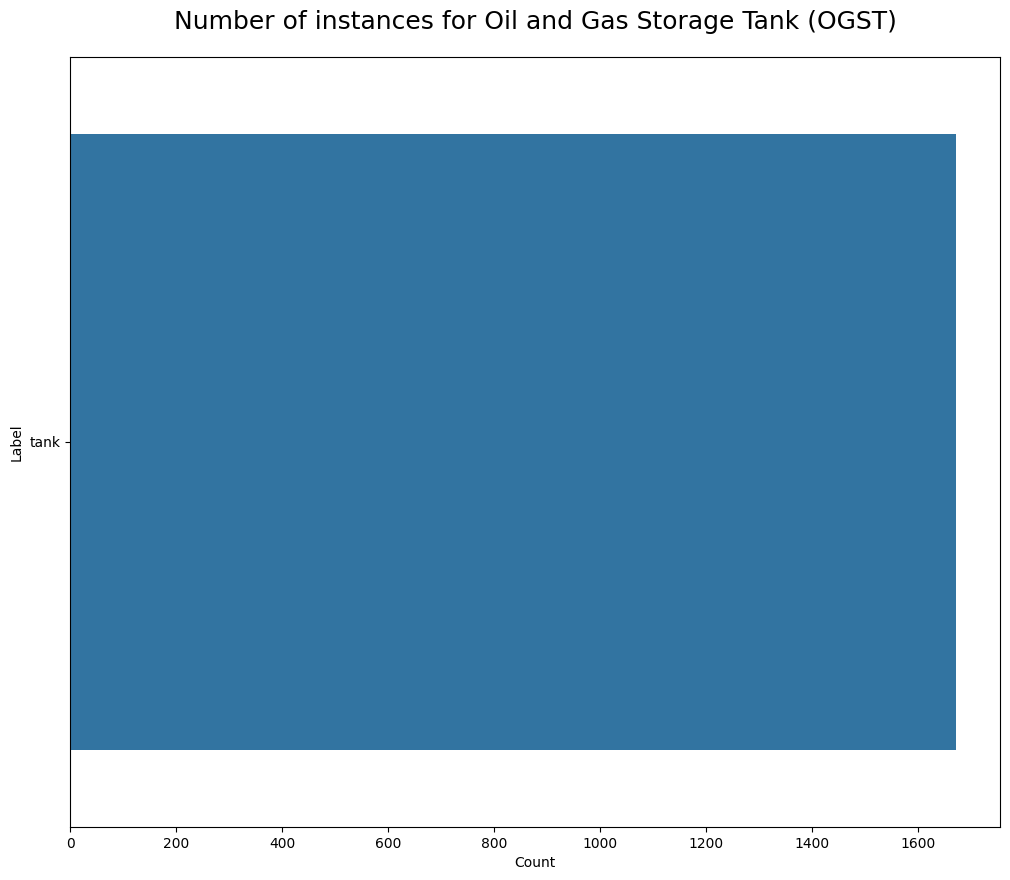

In [21]:
dataset.data_distribution_barchart();

## Load train data

In [22]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/OGST/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OGST/annotations/",
    "csv_file": "/home/dragik/data/FAIR_EO/OGST/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = OGSTDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 608


## Create the model

In [23]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/OGST/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [24]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-05 11:30:41,409 INFO Starting training.
training: 100%|██████████| 76/76 [00:25<00:00,  2.94it/s]
2025-05-05 11:31:07,669 INFO epoch: 1, time: 26, loss:  0.27626
testing on train set: 100%|██████████| 76/76 [00:13<00:00,  5.51it/s]
2025-05-05 11:31:23,369 INFO map:0.5491920113563538, map_50:0.9725289344787598, map_75:0.5575776100158691, map_small:0.5225517749786377, map_medium:0.5889222025871277, map_large:-1.0, mar_1:0.2933381497859955, mar_10:0.6047067046165466, mar_100:0.6180304288864136, mar_small:0.5844602584838867, mar_medium:0.6706319451332092, mar_large:-1.0, map_per_class:0.5491920113563538, mar_100_per_class:0.6180304288864136, classes:1.0
training: 100%|██████████| 76/76 [00:26<00:00,  2.92it/s]
2025-05-05 11:31:49,393 INFO epoch: 2, time: 26, loss:  0.20700
testing on train set: 100%|██████████| 76/76 [00:14<00:00,  5.23it/s]
2025-05-05 11:32:04,534 INFO map:0.6300675868988037, map_50:0.9773651957511902, map_75:0.771879255771637, map_small:0.6159197688102722, map_me

## Evaluate the model

In [26]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/OGST/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OGST/annotations/",
    "csv_file": "/home/dragik/data/FAIR_EO/OGST/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = OGSTDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/OGST/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 76


2025-05-05 11:38:34,477 INFO Loading checkpoint /home/dragik/data/FAIR_EO/OGST/experiments/checkpoint.pth.tar
2025-05-05 11:38:34,838 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/OGST/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 10/10 [00:02<00:00,  4.16it/s]


[{'map': 0.5116369724273682,
  'map_50': 0.9722402095794678,
  'map_75': 0.4633370041847229,
  'map_small': 0.5122178792953491,
  'map_medium': 0.5212520956993103,
  'map_large': -1.0,
  'mar_1': 0.30849674344062805,
  'mar_10': 0.5908496975898743,
  'mar_100': 0.5908496975898743,
  'mar_small': 0.591566264629364,
  'mar_medium': 0.5899999737739563,
  'mar_large': -1.0,
  'map_per_class': 0.5116369724273682,
  'mar_100_per_class': 0.5908496975898743,
  'classes': 1.0}]

## Predictions

2025-05-05 11:38:44,505 INFO Loading checkpoint /home/dragik/data/FAIR_EO/OGST/experiments/checkpoint.pth.tar
2025-05-05 11:38:44,865 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/OGST/experiments/checkpoint.pth.tar at epoch 11


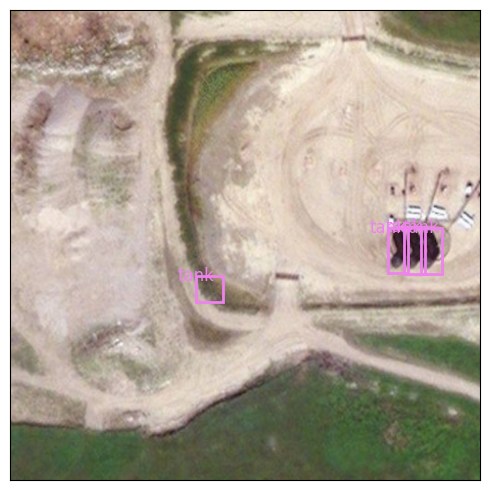

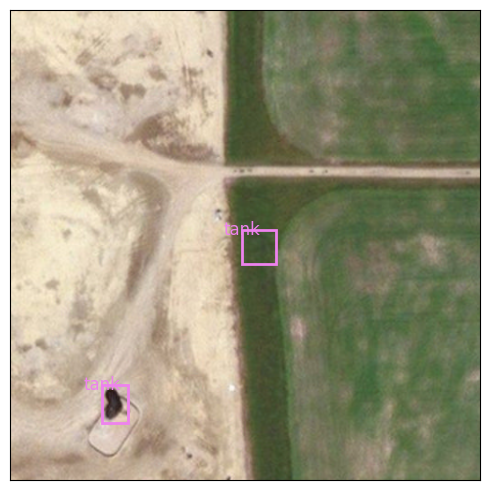

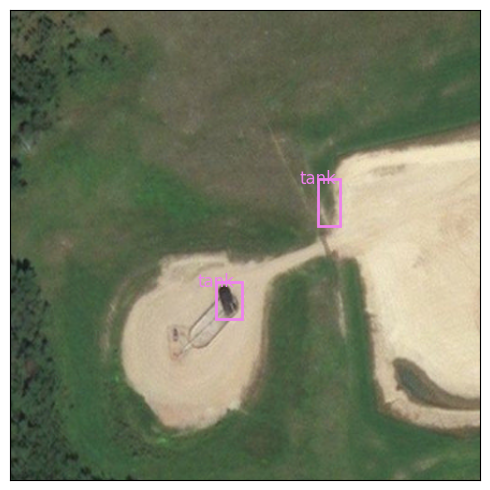

In [27]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/OGST/experiments/checkpoint.pth.tar"
labels = ["no-data", "tank"]
transform = Resize()
model.load_model(model_path)

csv_file = "/home/dragik/data/FAIR_EO/OGST/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/OGST/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/OGST/' + test_list[1])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/OGST/' + test_list[10])
fig = model.detect_objects(image, labels, transform)